### 实验2 神经网络应用案例与调优（4 葡萄酒分类预测）
#### （本实验仅做**红葡萄酒**的建模）

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入第三方库

In [1]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

In [2]:
from pathlib import Path
import json
import time
from datetime import datetime
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from torch.utils.tensorboard import SummaryWriter
torch.set_num_threads(2)

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, balanced_accuracy_score

（2）设置图表显示

In [ ]:
# 显式启用Notebook内嵌绘图，批量运行时也保留图表输出
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

import seaborn as sns

（3）观察设备情况，以便使用GPU

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [5]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

In [6]:
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR = OUTPUT_DIR / 'tensorboard' / datetime.now().strftime('%Y%m%d-%H%M%S')

##### 1.2 数据导入与初步观察
（1）读取数据并重命名字段

In [7]:
data_red = pd.read_csv('data/winequality-red.csv', sep=';')

rename_dict = {
    'fixed acidity': '固定酸',
    'volatile acidity': '挥发酸',
    'citric acid': '柠檬酸',
    'residual sugar': '残糖',
    'chlorides': '氯化物',
    'free sulfur dioxide': '游离二氧化硫',
    'total sulfur dioxide': '总二氧化硫',
    'density': '密度',
    'pH': 'pH',
    'sulphates': '硫酸盐',
    'alcohol': '酒精',
    'quality': '品质'
}

data_red = data_red.rename(columns=rename_dict)

data_red

,固定酸,挥发酸,柠檬酸,残糖,氯化物,游离二氧化硫,总二氧化硫,密度,pH,硫酸盐,酒精,品质
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [8]:
print('原始形状：', data_red.shape)
print('缺失值总数：', int(data_red.isna().sum().sum()))
print('完全重复记录数：', int(data_red.duplicated().sum()))
display(data_red.describe().round(3))
display(data_red['品质'].value_counts().sort_index().rename('样本数').to_frame())

原始形状： (1599, 12)
缺失值总数： 0
完全重复记录数： 240


,固定酸,挥发酸,柠檬酸,残糖,氯化物,游离二氧化硫,总二氧化硫,密度,pH,硫酸盐,酒精,品质
count,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000
mean,8.320,0.528,0.271,2.539,0.087,15.875,46.468,0.997,3.311,0.658,10.423,5.636
std,1.741,0.179,0.195,1.410,0.047,10.460,32.895,0.002,0.154,0.170,1.066,0.808
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,22.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.260,2.200,0.079,14.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.200,0.640,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.730,11.100,6.000
max,15.900,1.580,1.000,15.500,0.611,72.000,289.000,1.004,4.010,2.000,14.900,8.000


,样本数
品质,
3,10
4,53
5,681
6,638
7,199
8,18


（2）数据分布图

保留原有逐特征直方图的观察目的，合并为网格，便于比较不同量纲及偏态；品质单独作为离散标签观察。

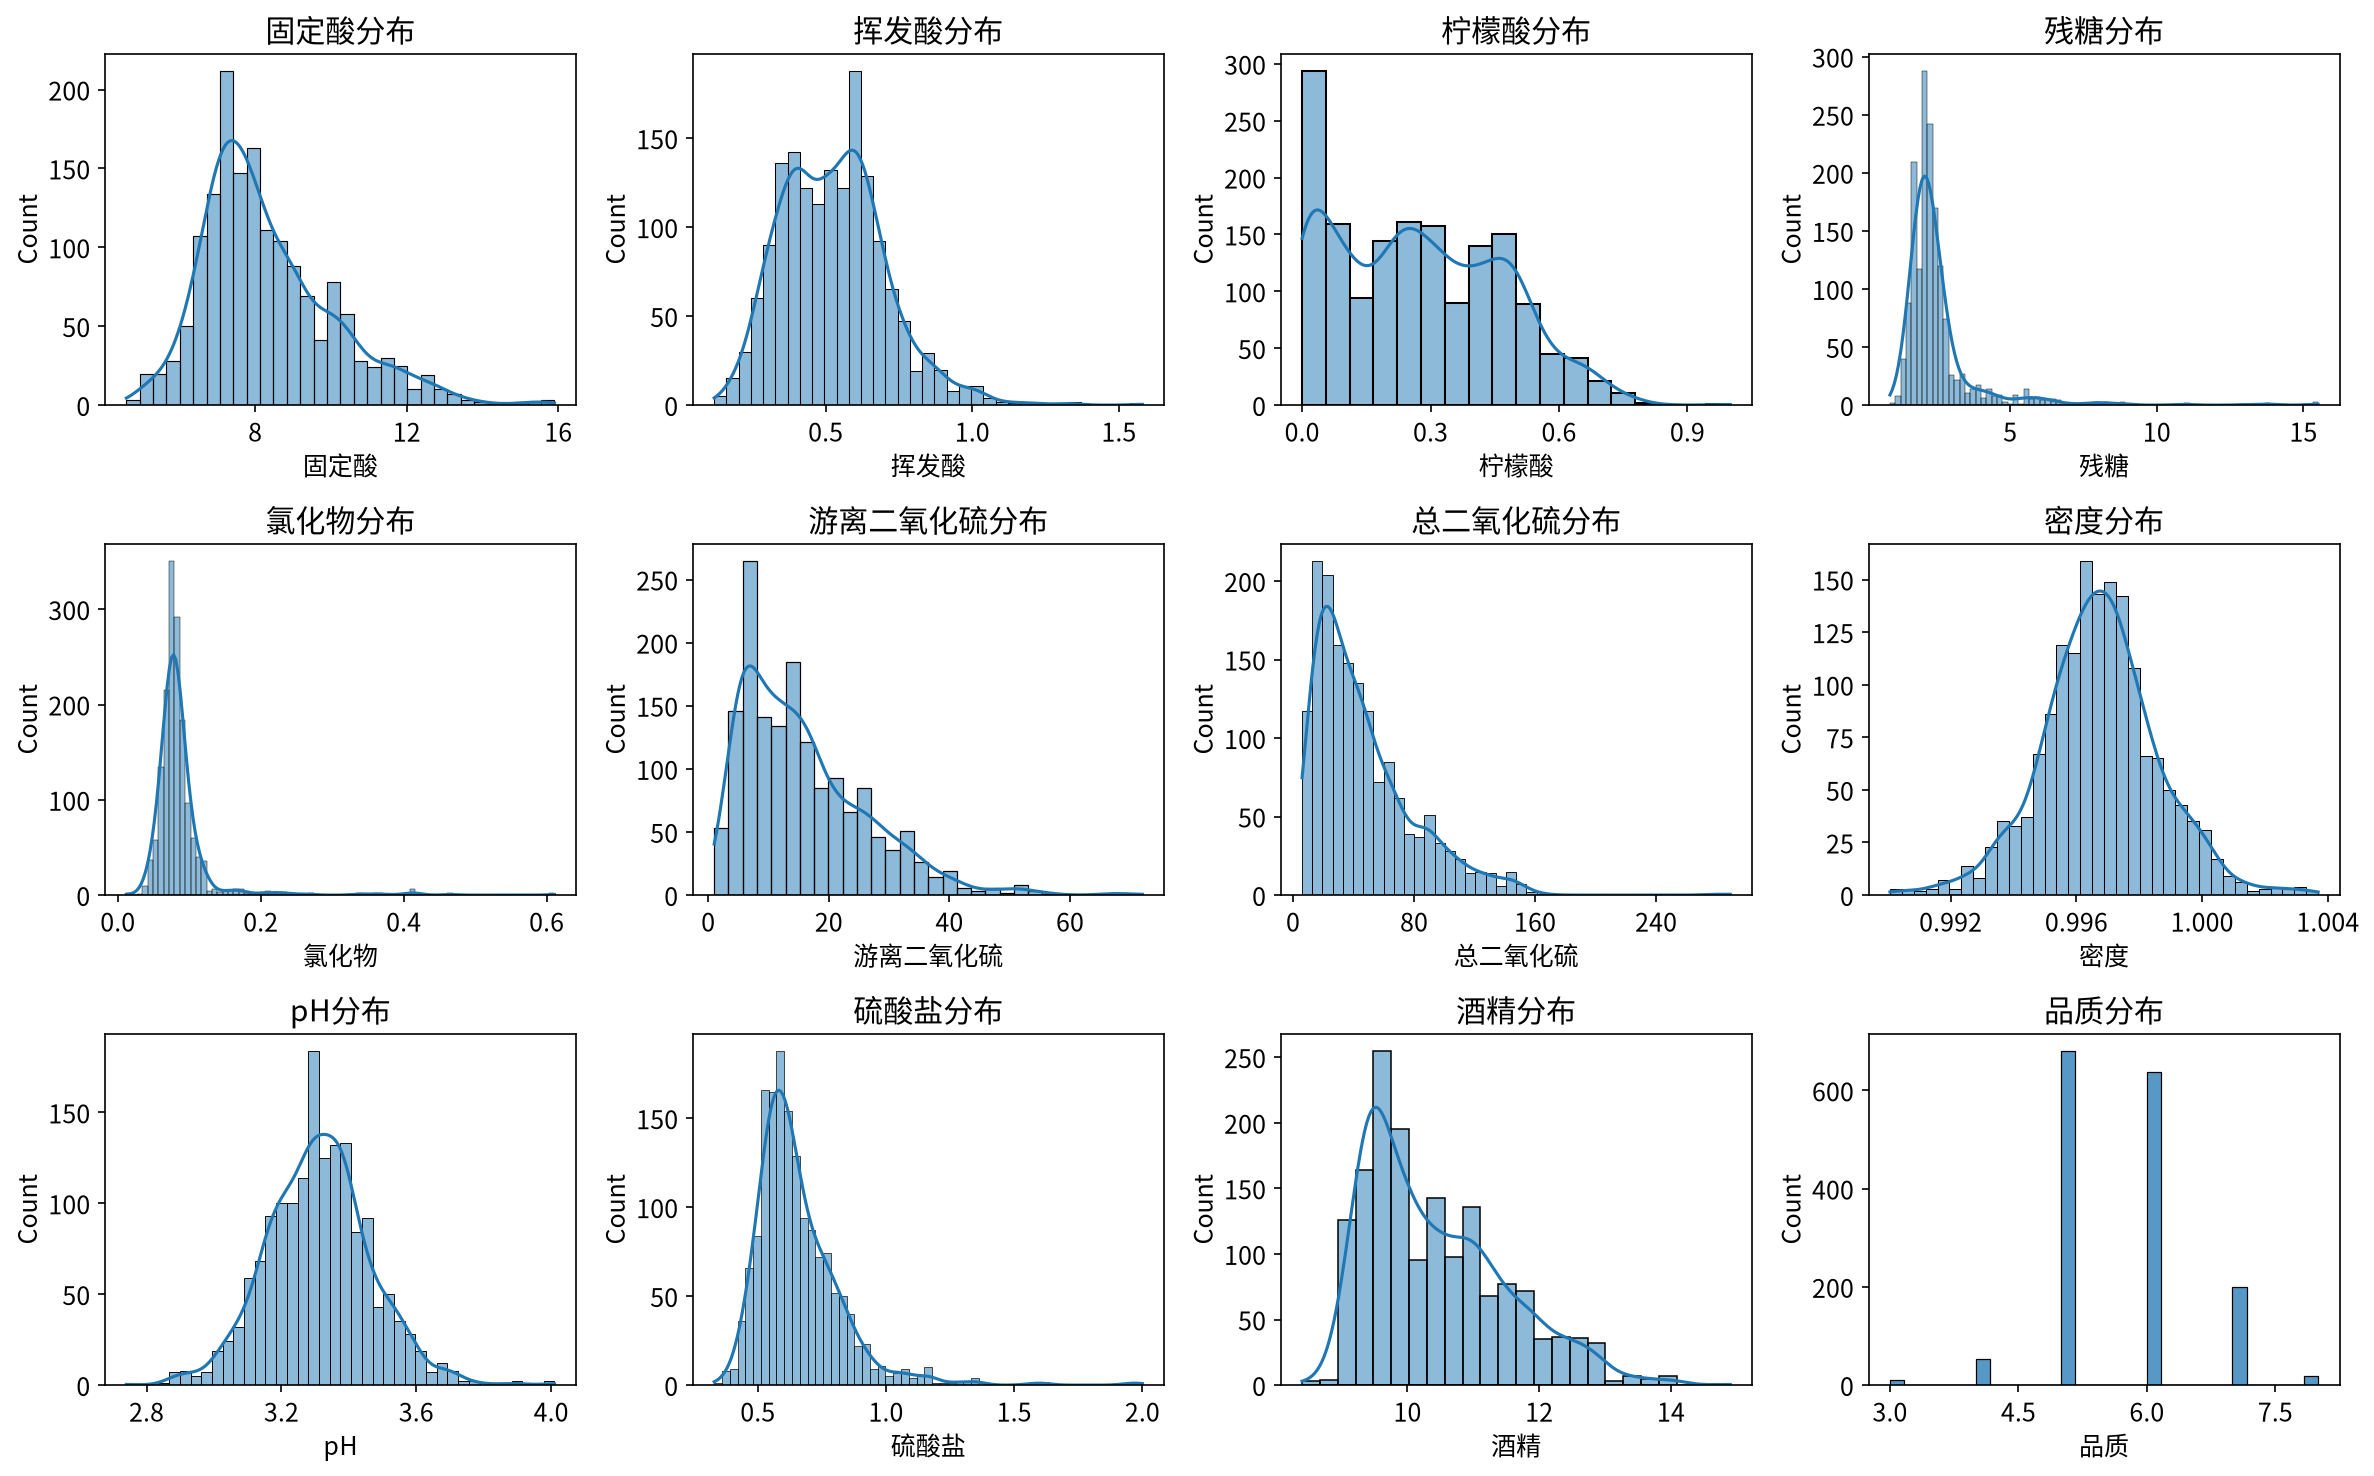

In [9]:
features = data_red.select_dtypes(include='number').columns
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for feature, ax in zip(features, axes.flat):
    sns.histplot(data=data_red, x=feature, kde=(feature != '品质'), ax=ax)
    ax.set_title(f'{feature}分布')
    ax.xaxis.set_major_locator(ticker.MaxNLocator(4))
plt.tight_layout()
plt.show()

##### 1.3 数据清理、划分与标准化
（1）完全重复记录去重后再分层划分为训练60%、验证20%、测试20%；缺失值若存在，使用训练集特征中位数填补

In [ ]:
clean_data = data_red.drop_duplicates().reset_index(drop=True)
train_data, heldout_data = train_test_split(
    clean_data, test_size=0.4, random_state=42, stratify=clean_data['品质'])

val_data, test_data = train_test_split(
    heldout_data, test_size=0.5, random_state=42, stratify=heldout_data['品质'])

feature_columns = [col for col in clean_data.columns if col != '品质']
quality_values = np.sort(train_data['品质'].unique())
quality_to_index = {int(q): i for i, q in enumerate(quality_values)}
N_CLASSES = len(quality_values)
medians = train_data[feature_columns].median()

x_train_raw = train_data[feature_columns].fillna(medians).to_numpy(dtype=np.float32)
x_val_raw = val_data[feature_columns].fillna(medians).to_numpy(dtype=np.float32)
x_test_raw = test_data[feature_columns].fillna(medians).to_numpy(dtype=np.float32)

y_train = train_data['品质'].map(quality_to_index).to_numpy(dtype=np.int64)
y_val = val_data['品质'].map(quality_to_index).to_numpy(dtype=np.int64)
y_test = test_data['品质'].map(quality_to_index).to_numpy(dtype=np.int64)

assert set(train_data.index).isdisjoint(val_data.index)
assert set(train_data.index).isdisjoint(test_data.index)
assert set(val_data.index).isdisjoint(test_data.index)

split_counts = pd.concat([d['品质'].value_counts().sort_index().rename(name)
                          for name, d in [('训练集', train_data), ('验证集', val_data),
                                          ('测试集', test_data)]], axis=1).fillna(0).astype(int)

print('去重后样本数：', len(clean_data))
print('训练/验证/测试：', len(train_data), len(val_data), len(test_data))
display(split_counts)
print('品质标签映射：', quality_to_index)

去重后样本数： 1359
训练/验证/测试： 815 272 272


,训练集,验证集,测试集
品质,,,
3,6,2,2
4,32,10,11
5,346,116,115
6,321,107,107
7,100,33,34
8,10,4,3


品质标签映射： {3: 0, 4: 1, 5: 2, 6: 3, 7: 4, 8: 5}


（2）仅用训练集拟合标准化器

逻辑回归与神经网络使用标准化特征，决策树使用原始特征；将品质3、4、5、6、7、8编码为0到5，以满足`CrossEntropyLoss`的标签范围要求

In [11]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train_raw).astype(np.float32)
x_val = scaler.transform(x_val_raw).astype(np.float32)
x_test = scaler.transform(x_test_raw).astype(np.float32)
print('训练集标准化后的均值：', x_train.mean(axis=0).round(3))
print('训练集标准化后的标准差：', x_train.std(axis=0).round(3))
# 只在训练集统计离群数量，不据此删除验证、测试记录。
z_scores = np.abs((x_train_raw - scaler.mean_) / scaler.scale_)
print('训练集存在任一3σ外特征的样本数：', int((z_scores > 3).any(axis=1).sum()))

训练集标准化后的均值： [ 0. -0.  0.  0. -0.  0.  0.  0. -0.  0. -0.]
训练集标准化后的标准差： [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
训练集存在任一3σ外特征的样本数： 73


（3）相关性分析

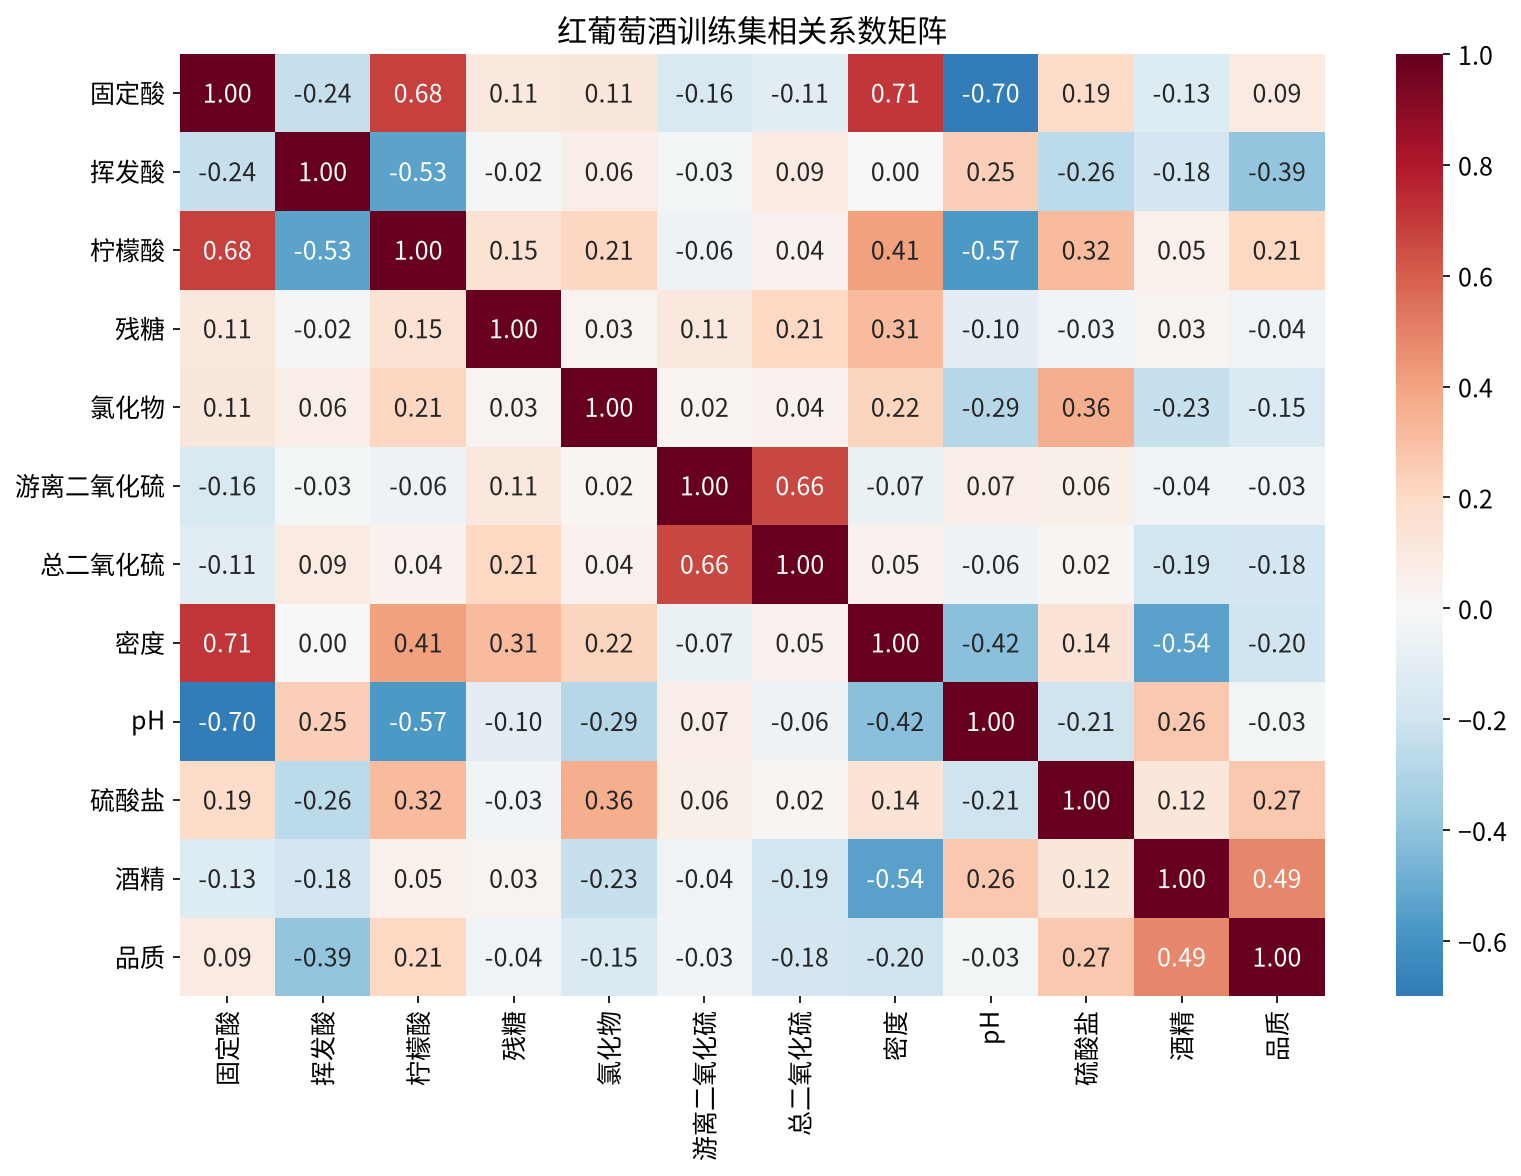

,与品质的Pearson相关系数
酒精,0.488513
挥发酸,-0.387896
硫酸盐,0.268207
柠檬酸,0.205728
密度,-0.201325
总二氧化硫,-0.181106
氯化物,-0.147254
固定酸,0.093543
残糖,-0.043216
游离二氧化硫,-0.031728


In [12]:
correlation = train_data[feature_columns + ['品质']].corr()
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(correlation, cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=ax)
ax.set_title('红葡萄酒训练集相关系数矩阵')
plt.tight_layout()
plt.show()
quality_correlation = correlation['品质'].drop('品质').sort_values(key=abs, ascending=False)
display(quality_correlation.rename('与品质的Pearson相关系数').to_frame())

#### 二、模型定义、参数调整与对比
##### 2.1 实验设计与公共评价函数

三种算法均在相同训练、验证、测试划分下比较。每种算法仅根据验证集Acc选择配置，以Macro-F1作为并列时的第二排序指标。分类不平衡，因此额外报告Macro-F1、Balanced Acc与品质MAE。多数类基准只使用训练标签确定。

| 模型 | 参数尝试 | 调参依据 |
| :---: | :--- | :--- |
| 决策树 | max_depth=3/5/8/None，min_samples_leaf=1/5/15，class_weight=None/balanced | 验证Acc，随后Macro-F1 |
| PyTorch多项逻辑回归 | L2系数=0/0.0001/0.001/0.01，学习率0.01 | 验证Acc，随后Macro-F1 |
| PyTorch神经网络 | 32、64、64-32、128-64，Dropout与L2对比 | 验证Acc，随后Macro-F1 |

使用验证集早停，深度模型以最低验证Loss恢复权重，然后比较验证Acc

In [ ]:
def make_loader(x, y, batch=128, shuffle=False, seed=42):
    # 固定抽样顺序；验证和测试不打乱，也不丢弃最后一个不完整batch。
    generator = torch.Generator().manual_seed(seed)
    dataset = TensorDataset(torch.as_tensor(x, dtype=torch.float32),
                            torch.tensor(y, dtype=torch.long))
    return DataLoader(dataset, batch_size=batch, shuffle=shuffle, generator=generator)


@torch.no_grad()
def evaluate_loader(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    targets, predictions, probabilities = [], [], []
    for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        logits = model(bx)
        loss = nn.functional.cross_entropy(logits, by)
        # 必须累加所有batch的总损失，而非覆盖为最后一个batch的损失。
        loss_sum += loss.item() * by.size(0)
        pred = logits.argmax(dim=1)
        correct += (pred == by).sum().item()
        count += by.size(0)
        targets.extend(by.cpu().tolist())
        predictions.extend(pred.cpu().tolist())
        probabilities.extend(logits.softmax(dim=1).cpu().tolist())
    return {'Loss': loss_sum / count, 'Acc': correct / count,
            'Macro_F1': f1_score(targets, predictions, labels=list(range(N_CLASSES)),
                                 average='macro', zero_division=0),
            'y_true': np.array(targets), 'y_pred': np.array(predictions),
            'probabilities': np.array(probabilities)}


def train_and_val_model(model, epochs, batch, run_name, learning_rate=0.001,
                        weight_decay=0.0, patience=None, target_acc=None,
                        optimizer_name='RMSprop', schedule=False):
    # 模型先迁移设备，再创建优化器，避免优化器引用失效。
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer_cls = {'RMSprop': optim.RMSprop, 'Adam': optim.Adam}[optimizer_name]
    optimizer = optimizer_cls(model.parameters(), lr=learning_rate,weight_decay=weight_decay)
    
    scheduler = (optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-5)
        if schedule else None)
    
    train_loader = make_loader(x_train, y_train, batch, shuffle=True)
    train_eval_loader = make_loader(x_train, y_train, batch)
    val_loader = make_loader(x_val, y_val, batch)

    checkpoint = OUTPUT_DIR / 'checkpoints' / f'{run_name}.pt'
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    writer = SummaryWriter(str(LOG_DIR / run_name))
    best_loss, best_epoch, wait = float('inf'), 0, 0
    rows, stop_reason = [], '达到最大训练轮次'

    start = time.perf_counter()
    try:
        # TensorBoard记录真实模型计算图。
        sample = torch.as_tensor(x_train[:2], dtype=torch.float32, device=device)
        writer.add_graph(model, sample)
        for epoch in range(1, epochs + 1):
            model.train()
            for bx, by in train_loader:
                bx, by = bx.to(device), by.to(device)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(bx), by)
                loss.backward()
                optimizer.step()
            # 每轮结束后用同一模型状态评估训练集与验证集，口径一致。
            tr = evaluate_loader(model, train_eval_loader)
            va = evaluate_loader(model, val_loader)
            lr = optimizer.param_groups[0]['lr']
            rows.append([epoch, tr['Loss'], tr['Acc'], va['Loss'], va['Acc'], lr])
            for split, result in [('train', tr), ('val', va)]:
                writer.add_scalar(f'Loss/{split}', result['Loss'], epoch)
                writer.add_scalar(f'Accuracy/{split}', result['Acc'], epoch)
            writer.add_scalar('Learning_rate', lr, epoch)
            if epoch == 1 or epoch % 5 == 0:
                for name, parameter in model.named_parameters():
                    writer.add_histogram(f'Parameters/{name}', parameter, epoch)
            # 保存验证损失最低的权重，早停触发时也不会误用最后一轮权重。
            if va['Loss'] < best_loss:
                best_loss, best_epoch, wait = va['Loss'], epoch, 0
                torch.save({'model_state_dict': model.state_dict(),
                            'best_epoch': epoch, 'val_loss': best_loss,
                            'run_name': run_name}, checkpoint)
            else:
                wait += 1
            if scheduler is not None:
                scheduler.step(va['Loss'])
            if target_acc is not None and va['Acc'] >= target_acc:
                stop_reason = f'验证Acc达到阈值{target_acc:.0%}'
                break
            if patience is not None and wait >= patience:
                stop_reason = f'验证Loss连续{patience}轮未改善，早停'
                break
    finally:
        writer.close()
    state = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(state['model_state_dict'])
    history = pd.DataFrame(rows, columns=['Epoch', 'Train_Loss', 'Train_Acc',
                                         'Val_Loss', 'Val_Acc', 'Learning_Rate'])
    history.to_csv(OUTPUT_DIR / f'{run_name}_history.csv', index=False)
    info = {'Best_Epoch': best_epoch, 'Actual_Epochs': len(history),
            'Stop_Reason': stop_reason, 'Seconds': time.perf_counter() - start,
            'Checkpoint': str(checkpoint)}
    print(f"{run_name}: 训练{len(history)}轮，最佳轮次{best_epoch}；{stop_reason}")
    return model, history, info


def plot_multiple_models_train_result(results_dict, title):
    # 沿用ex-1.2的对比绘图方式，同时补上验证集指标。
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    for name, history in results_dict.items():
        for ax, key in zip(axes.flat, ['Train_Loss', 'Val_Loss', 'Train_Acc', 'Val_Acc']):
            ax.plot(history['Epoch'], history[key], label=name, linewidth=1.6)
            ax.set_title(key)
            ax.set_xlabel('Epoch')
            ax.grid(alpha=0.3)
            
            if 'Acc' in key:
                ax.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))

    axes[0, 0].legend(fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [ ]:
def metric_row(target, prediction):
    return {'Acc': accuracy_score(target, prediction),
            'Macro_F1': f1_score(target, prediction, labels=list(range(N_CLASSES)), average='macro', zero_division=0),
            'Balanced_Acc': balanced_accuracy_score(target, prediction),
            'MAE': mean_absolute_error(quality_values[target], quality_values[prediction])}

majority_class = int(pd.Series(y_train).mode().iloc[0])
majority_val = metric_row(y_val, np.full_like(y_val, majority_class))
print('训练集确定的多数类：', quality_values[majority_class])
print('多数类验证集基准：', majority_val)
candidates, selected = {}, {}

训练集确定的多数类： 5
多数类验证集基准： {'Acc': 0.4264705882352941, 'Macro_F1': 0.09965635738831614, 'Balanced_Acc': 0.16666666666666666, 'MAE': 0.7316176470588235}


##### 2.2 决策树分类器
（1）以CART分类树建模。通过最大深度、叶子最少样本数限制过拟合，同时比较是否使用类别平衡权重；每个组合重新拟合。

In [15]:
tree_rows, tree_models = [], {}
for depth in [3, 5, 8, None]:
    for leaf in [1, 5, 15]:
        for weight in [None, 'balanced']:
            name = f'depth={depth}, leaf={leaf}, weight={weight}'
            model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                           class_weight=weight, random_state=42)
            model.fit(x_train_raw, y_train)
            val_metrics = metric_row(y_val, model.predict(x_val_raw))
            tree_models[name] = model
            tree_rows.append({'Config': name, **val_metrics,
                              'Train_Acc': model.score(x_train_raw, y_train)})
tree_table = pd.DataFrame(tree_rows).sort_values(['Acc', 'Macro_F1'], ascending=False)
tree_name = tree_table.iloc[0]['Config']
selected['决策树'] = {'name': tree_name, 'model': tree_models[tree_name],
                    'validation': tree_table.iloc[0].to_dict()}
candidates['决策树'] = tree_table
display(tree_table.style.format({'Acc': '{:.2%}', 'Macro_F1': '{:.4f}',
                                 'Balanced_Acc': '{:.4f}', 'MAE': '{:.4f}',
                                 'Train_Acc': '{:.2%}'}).hide(axis='index'))
print('决策树最佳配置：', tree_name)

Config,Acc,Macro_F1,Balanced_Acc,MAE,Train_Acc
"depth=5, leaf=15, weight=None",56.62%,0.2793,0.2871,0.4890,66.01%
"depth=5, leaf=1, weight=None",55.15%,0.2719,0.2743,0.4963,67.48%
"depth=8, leaf=5, weight=None",54.41%,0.2830,0.2816,0.5257,75.95%
"depth=5, leaf=5, weight=None",53.68%,0.2683,0.2724,0.5110,67.36%
"depth=None, leaf=5, weight=None",52.94%,0.2769,0.2786,0.5551,80.74%
"depth=8, leaf=1, weight=None",52.94%,0.2726,0.2655,0.5294,83.80%
"depth=8, leaf=15, weight=None",52.94%,0.2647,0.2720,0.5331,69.08%
"depth=None, leaf=15, weight=None",52.57%,0.2636,0.2709,0.5331,69.33%
"depth=None, leaf=1, weight=None",52.21%,0.2861,0.2834,0.5772,100.00%
"depth=3, leaf=1, weight=None",51.47%,0.1884,0.2088,0.5257,60.00%


决策树最佳配置： depth=5, leaf=15, weight=None


结论：决策树按验证集选择`depth=5, leaf=15, weight=None`，验证Acc为**56.62%**，Macro-F1为0.2793。上表完整保留所有候选参数的结果；测试集比较统一放在第三部分。

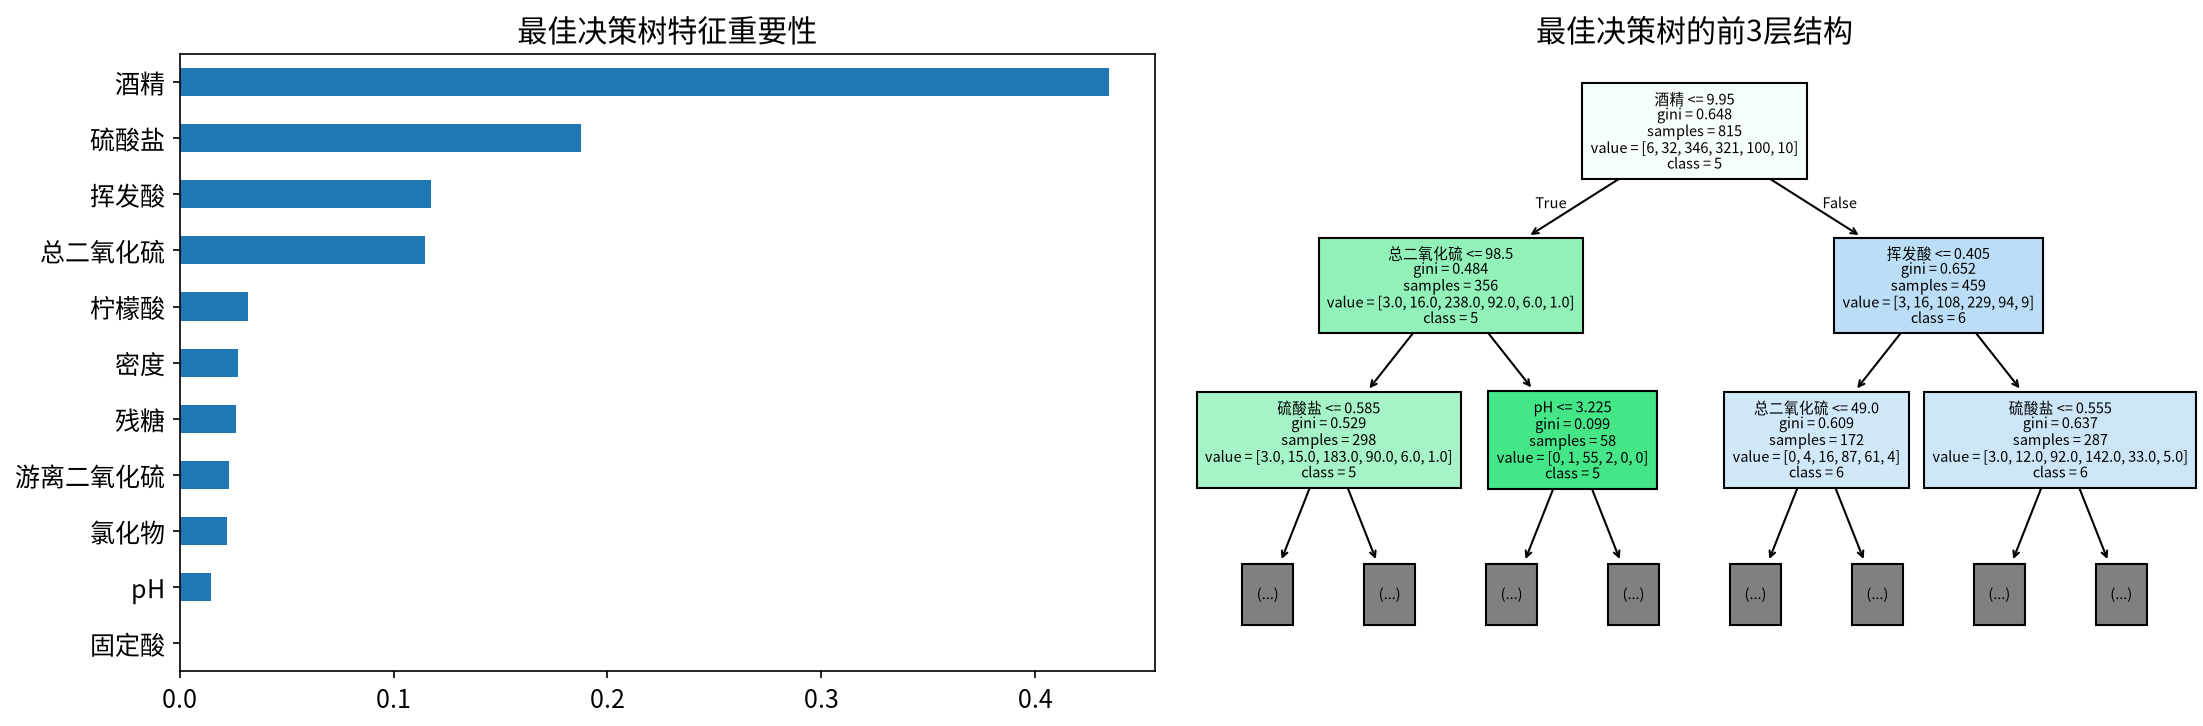

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance = pd.Series(selected['决策树']['model'].feature_importances_, index=feature_columns).sort_values()
importance.plot.barh(ax=axes[0], title='最佳决策树特征重要性')
plot_tree(selected['决策树']['model'], feature_names=feature_columns,
          class_names=[str(q) for q in quality_values], max_depth=2,
          filled=True, fontsize=7, ax=axes[1])
axes[1].set_title('最佳决策树的前3层结构')
plt.tight_layout()
plt.show()

##### 2.3 逻辑回归分类器
（1）无隐藏层的`Linear(11, 6)`输出各品质的logits，结合交叉熵训练，即为多项逻辑回归；预测时Softmax转为概率，使用argmax得到等级。
RMSprop/Adam优化器中的`weight_decay`用于L2正则化，控制系数大小。比较4个正则化强度；每次训练使用Adam、学习率0.01、batch=128，最多200轮、patience=20。

logistic_l2_0.0: 训练110轮，最佳轮次90；验证Loss连续20轮未改善，早停


logistic_l2_0.0001: 训练110轮，最佳轮次90；验证Loss连续20轮未改善，早停


logistic_l2_0.001: 训练110轮，最佳轮次90；验证Loss连续20轮未改善，早停


logistic_l2_0.01: 训练110轮，最佳轮次90；验证Loss连续20轮未改善，早停


Config,L2,Acc,Macro_F1,Balanced_Acc,MAE,Best_Epoch,Actual_Epochs,Stop_Reason,Seconds
logistic_l2_0.0,0.000000,58.09%,0.2822,0.281483,0.4669,90,110,验证Loss连续20轮未改善，早停,1.238455
logistic_l2_0.0001,0.000100,57.35%,0.2756,0.274875,0.4743,90,110,验证Loss连续20轮未改善，早停,1.043556
logistic_l2_0.001,0.001000,57.35%,0.2756,0.274875,0.4743,90,110,验证Loss连续20轮未改善，早停,1.025320
logistic_l2_0.01,0.010000,55.88%,0.2632,0.261537,0.4853,90,110,验证Loss连续20轮未改善，早停,1.018073


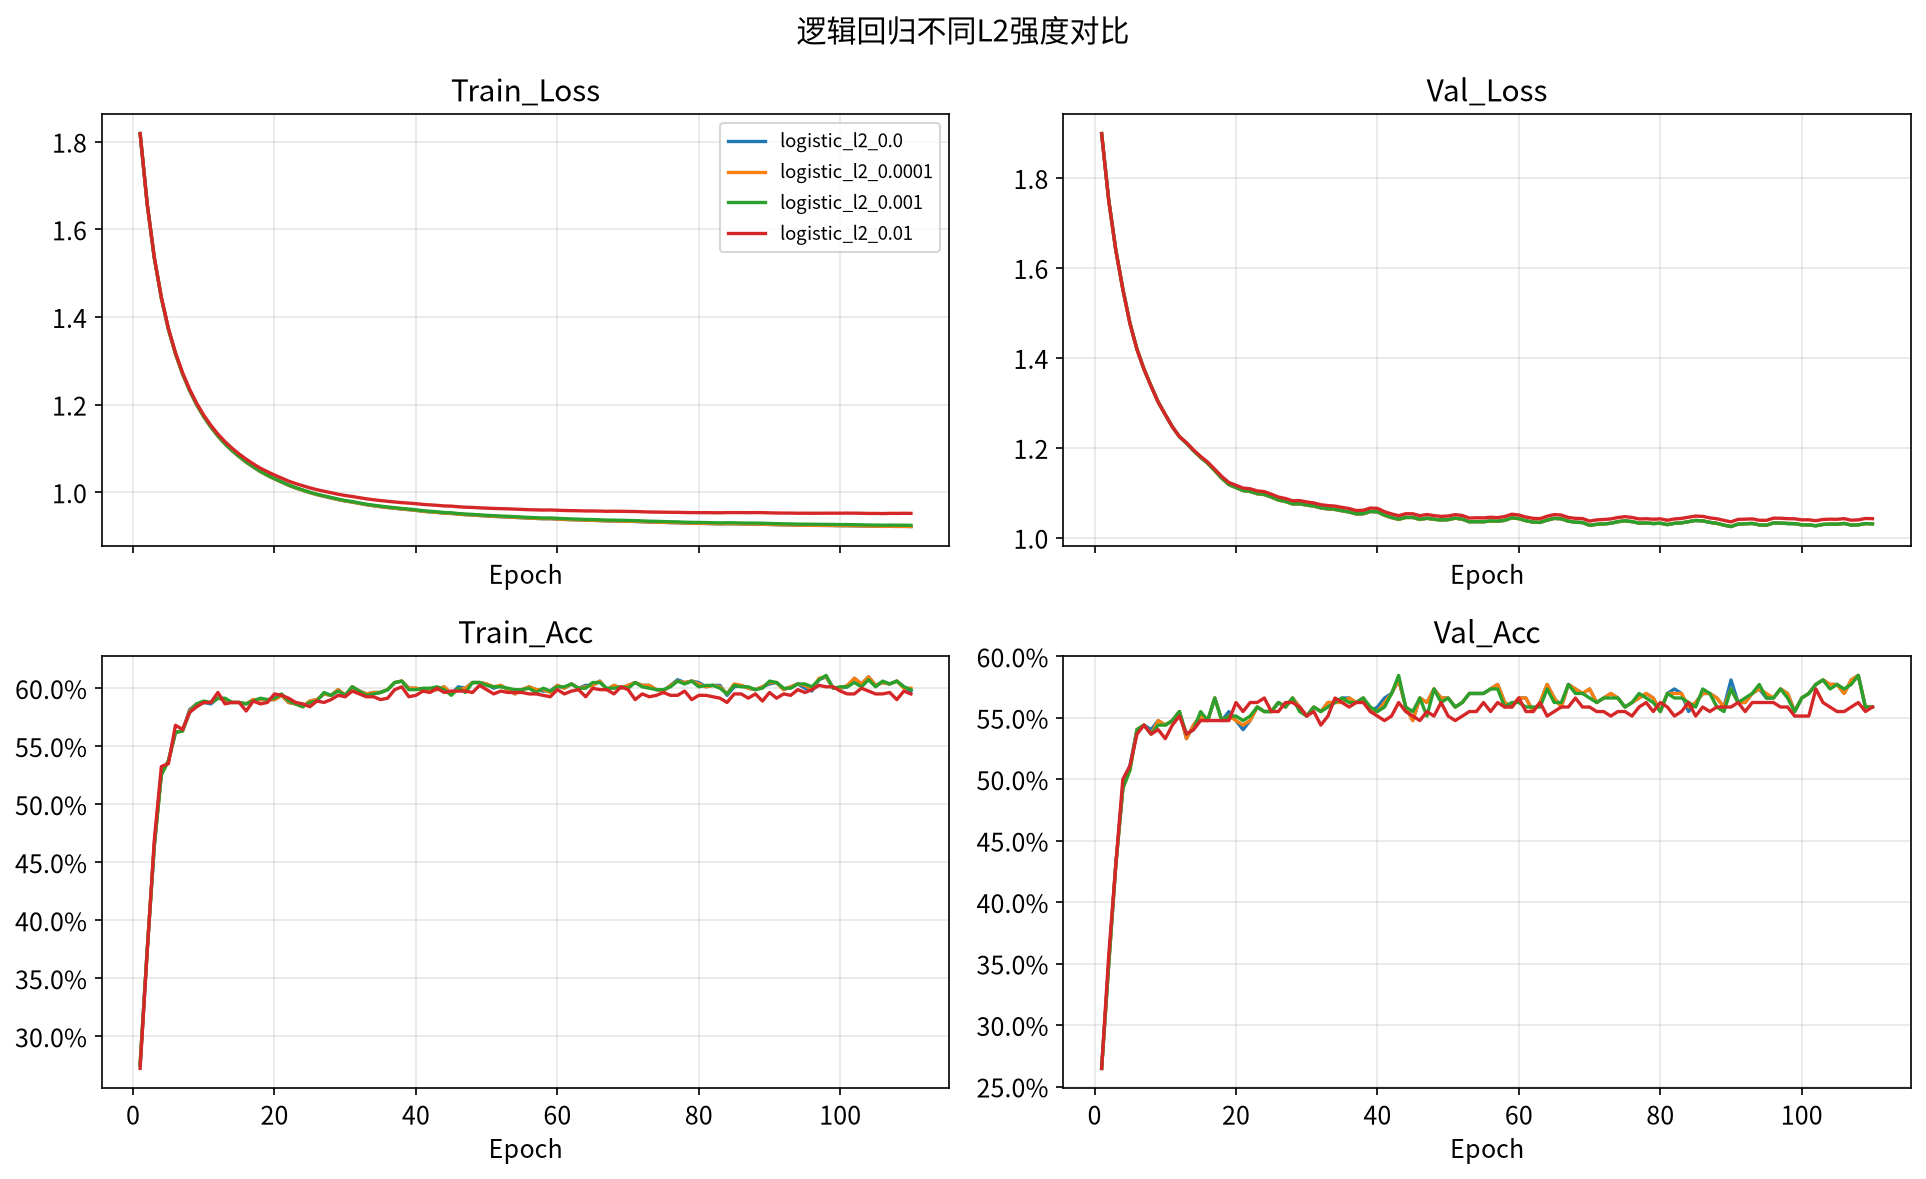

In [ ]:
class LogisticNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.out = nn.Linear(11, N_CLASSES)

    def forward(self, x):
        return self.out(x)

logistic_rows, logistic_models, logistic_histories = [], {}, {}
for strength in [0.0, 0.0001, 0.001, 0.01]:
    set_seed(42)
    name = f'logistic_l2_{strength}'
    model, history, info = train_and_val_model(
        LogisticNet(), epochs=200, batch=128, run_name=name,
        learning_rate=0.01, weight_decay=strength,
        patience=20, optimizer_name='Adam')
    val_metrics = evaluate_loader(model, make_loader(x_val, y_val, 128))
    row = {'Config': name, 'L2': strength,
           **metric_row(y_val, val_metrics['y_pred']), **info}
    logistic_rows.append(row)
    logistic_models[name] = model
    logistic_histories[name] = history

logistic_table = pd.DataFrame(logistic_rows).sort_values(['Acc', 'Macro_F1'], ascending=False)
logistic_name = logistic_table.iloc[0]['Config']
selected['逻辑回归'] = {'name': logistic_name, 'model': logistic_models[logistic_name],
                      'validation': logistic_table.iloc[0].to_dict()}
candidates['逻辑回归'] = logistic_table

display(logistic_table.drop(columns='Checkpoint').style.format(
    {'Acc': '{:.2%}', 'Macro_F1': '{:.4f}', 'MAE': '{:.4f}'}).hide(axis='index'))
plot_multiple_models_train_result(logistic_histories, '逻辑回归不同L2强度对比')

结论：逻辑回归按验证集选择`logistic_l2_0.0`，验证Acc为**58.09%**，Macro-F1为0.2822。上表完整保留所有候选参数的结果；测试集比较统一放在第三部分。

##### 2.4 神经网络分类器
（1）使用全连接层和ReLU学习非线性关系，输出6个原始品质类别。比较不同隐藏层宽度、深度，以及Dropout/L2设置。每个候选独立初始化，Adam学习率0.001，验证Loss连续15轮未改善时早停，并降低平台期学习率。

nn_32: 训练87轮，最佳轮次72；验证Loss连续15轮未改善，早停


nn_64: 训练68轮，最佳轮次53；验证Loss连续15轮未改善，早停


nn_64_32: 训练55轮，最佳轮次40；验证Loss连续15轮未改善，早停


nn_128_64: 训练33轮，最佳轮次18；验证Loss连续15轮未改善，早停


nn_dropout: 训练82轮，最佳轮次67；验证Loss连续15轮未改善，早停


nn_dropout_l2: 训练82轮，最佳轮次67；验证Loss连续15轮未改善，早停


Config,Hidden,Dropout,L2,Acc,Macro_F1,Balanced_Acc,MAE,Best_Epoch,Actual_Epochs,Stop_Reason,Seconds
nn_64_32,"(64, 32)",0.000000,0.000000,62.50%,0.3072,0.310411,0.4154,40,55,验证Loss连续15轮未改善，早停,0.796115
nn_dropout_l2,"(64, 32)",0.200000,0.001000,62.50%,0.3024,0.306677,0.4154,67,82,验证Loss连续15轮未改善，早停,1.304161
nn_dropout,"(64, 32)",0.200000,0.000000,61.76%,0.2994,0.303561,0.4154,67,82,验证Loss连续15轮未改善，早停,1.256017
nn_128_64,"(128, 64)",0.000000,0.000000,61.03%,0.3029,0.304301,0.4265,18,33,验证Loss连续15轮未改善，早停,0.503854
nn_64,"(64,)",0.000000,0.000000,59.19%,0.2882,0.289648,0.4485,53,68,验证Loss连续15轮未改善，早停,0.872227
nn_32,"(32,)",0.000000,0.000000,58.82%,0.2844,0.287849,0.4522,72,87,验证Loss连续15轮未改善，早停,1.144122


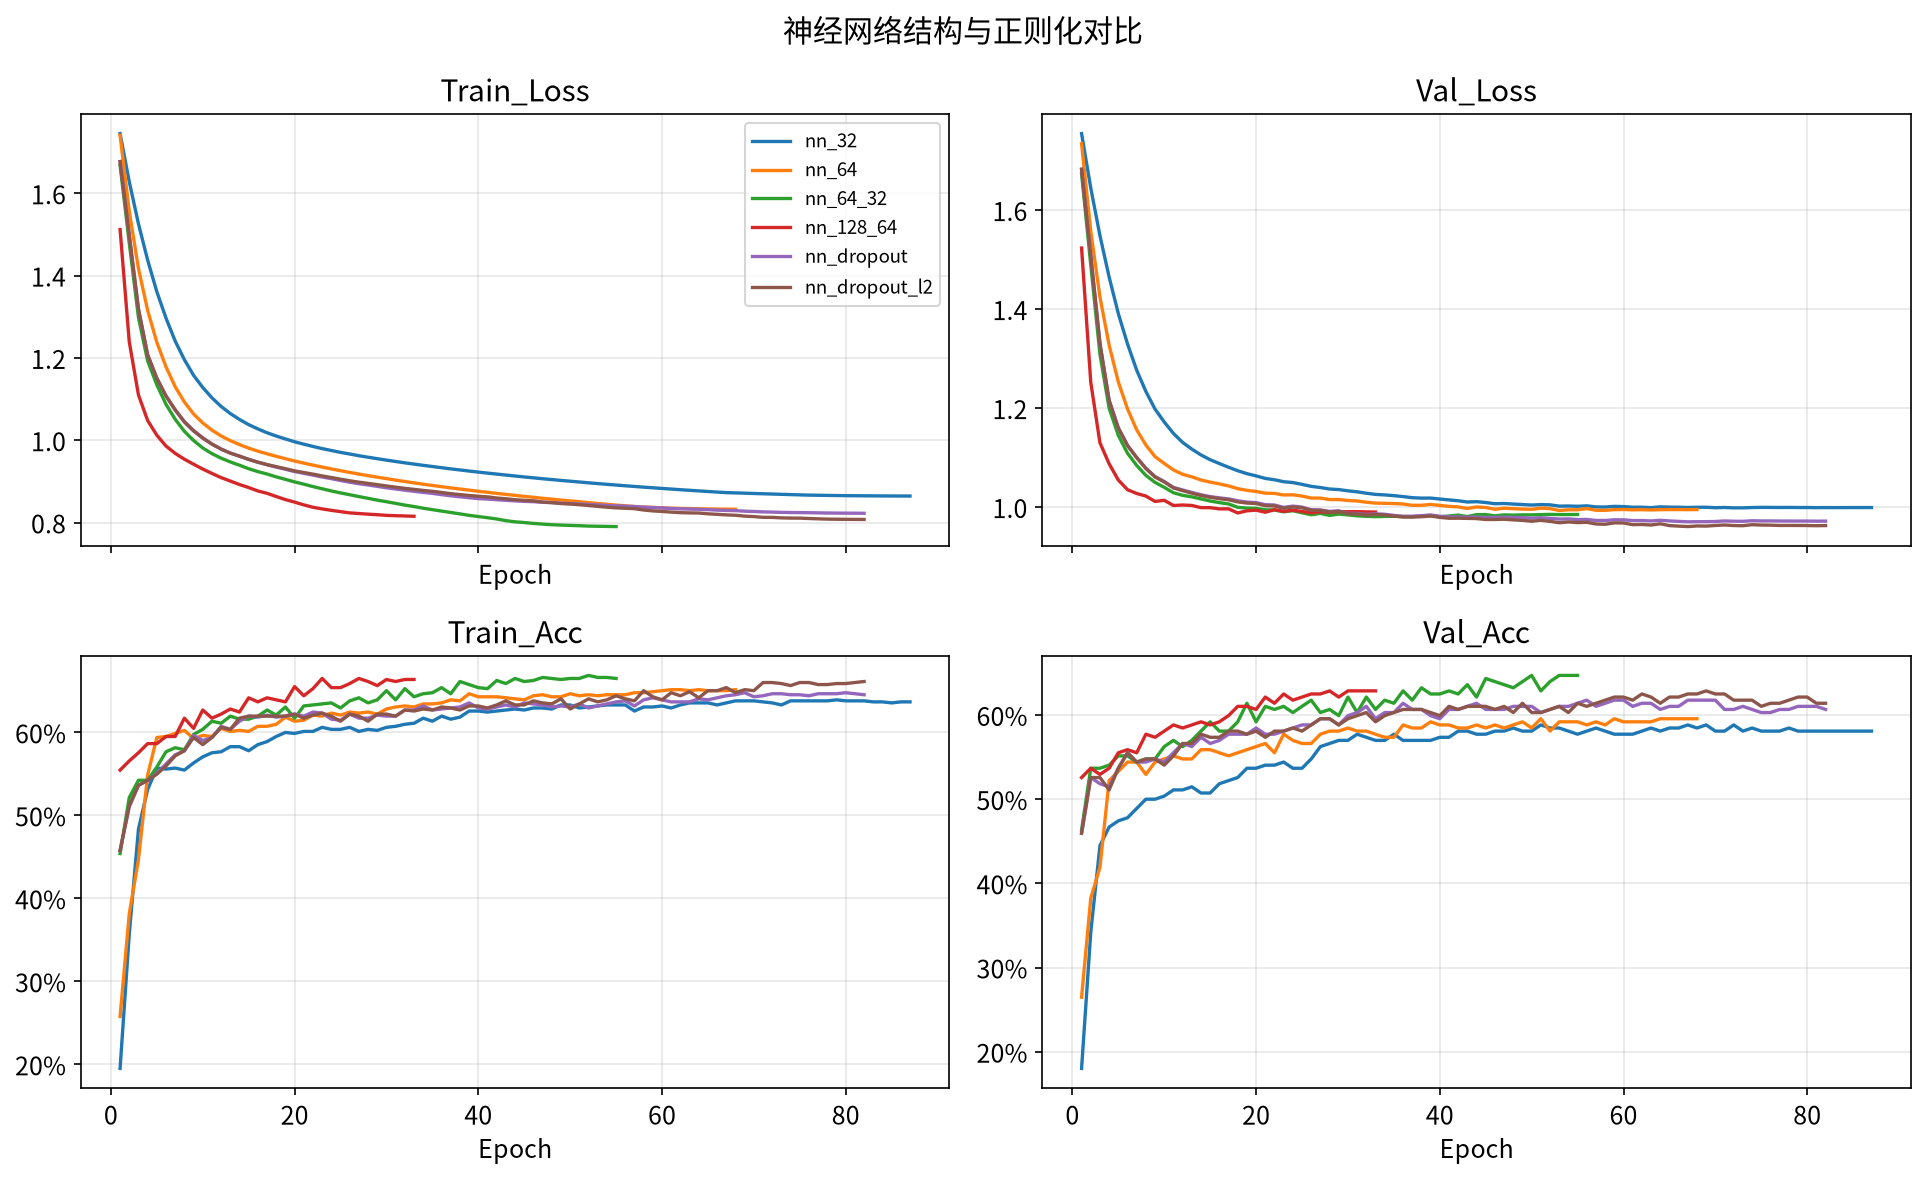

In [ ]:
class Net(nn.Module):
    def __init__(self, hidden=(64, 32), dropout=0.0):
        super().__init__()
        layers, size = [], 11
        for width in hidden:
            layers.extend([nn.Linear(size, width), nn.ReLU()])
            if dropout:
                layers.append(nn.Dropout(dropout))
            size = width
        layers.append(nn.Linear(size, N_CLASSES))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

nn_configs = [
    {'name': 'nn_32', 'hidden': (32,), 'dropout': 0.0, 'l2': 0.0},
    {'name': 'nn_64', 'hidden': (64,), 'dropout': 0.0, 'l2': 0.0},
    {'name': 'nn_64_32', 'hidden': (64, 32), 'dropout': 0.0, 'l2': 0.0},
    {'name': 'nn_128_64', 'hidden': (128, 64), 'dropout': 0.0, 'l2': 0.0},
    {'name': 'nn_dropout', 'hidden': (64, 32), 'dropout': 0.2, 'l2': 0.0},
    {'name': 'nn_dropout_l2', 'hidden': (64, 32), 'dropout': 0.2, 'l2': 0.001},
]
nn_rows, nn_models, nn_histories = [], {}, {}
for config in nn_configs:
    set_seed(42)
    name = config['name']
    model, history, info = train_and_val_model(
        Net(config['hidden'], config['dropout']), epochs=180, batch=64,
        run_name=name, learning_rate=0.001, weight_decay=config['l2'],
        patience=15, optimizer_name='Adam', schedule=True)
    
    result = evaluate_loader(model, make_loader(x_val, y_val, 128))
    nn_rows.append({'Config': name, 'Hidden': str(config['hidden']),
                    'Dropout': config['dropout'], 'L2': config['l2'],
                    **metric_row(y_val, result['y_pred']), **info})
    nn_models[name], nn_histories[name] = model, history

nn_table = pd.DataFrame(nn_rows).sort_values(['Acc', 'Macro_F1'], ascending=False)
nn_name = nn_table.iloc[0]['Config']

selected['神经网络'] = {'name': nn_name, 'model': nn_models[nn_name], 'validation': nn_table.iloc[0].to_dict()}
candidates['神经网络'] = nn_table

display(nn_table.drop(columns='Checkpoint').style.format({'Acc': '{:.2%}', 'Macro_F1': '{:.4f}', 'MAE': '{:.4f}'}).hide(axis='index'))
plot_multiple_models_train_result(nn_histories, '神经网络结构与正则化对比')

结论：神经网络按验证集选择`nn_64_32`，验证Acc为**62.50%**，Macro-F1为0.3072。上表完整保留所有候选参数的结果；测试集比较统一放在第三部分。

#### 三、较优模型比较、保存与预测
##### 3.1 验证集确定三种算法的较优模型
（1）下面每行对应各算法在验证集上选出的较优配置；总体模型也在查看测试结果之前固定。测试集不参与标准化、调参或早停。

In [19]:
validation_table = pd.DataFrame([
    {'Algorithm': algorithm, 'Config': item['name'],
     **{k: item['validation'][k] for k in ['Acc', 'Macro_F1', 'Balanced_Acc', 'MAE']}}
    for algorithm, item in selected.items()]).sort_values(['Acc', 'Macro_F1'], ascending=False)
best_algorithm = validation_table.iloc[0]['Algorithm']
print('按验证集选出的总体模型：', best_algorithm, selected[best_algorithm]['name'])
display(validation_table.style.format({'Acc': '{:.2%}', 'Macro_F1': '{:.4f}',
                                       'Balanced_Acc': '{:.4f}', 'MAE': '{:.4f}'}).hide(axis='index'))

按验证集选出的总体模型： 神经网络 nn_64_32


Algorithm,Config,Acc,Macro_F1,Balanced_Acc,MAE
神经网络,nn_64_32,62.50%,0.3072,0.3104,0.4154
逻辑回归,logistic_l2_0.0,58.09%,0.2822,0.2815,0.4669
决策树,"depth=5, leaf=15, weight=None",56.62%,0.2793,0.2871,0.4890


##### 3.2 测试集统一评价
（1）同时评价三种算法的较优模型与多数类基准。Macro-F1对每个等级等权，更能反映少数类别表现；品质MAE越小，错分的等级距离越小。

In [ ]:
predictions, comparison_rows = {}, []
for algorithm, item in selected.items():
    model = item['model']
    pred = (model.predict(x_test_raw) if algorithm == '决策树'
            else evaluate_loader(model, make_loader(x_test, y_test, 128))['y_pred'])
    predictions[algorithm] = pred
    comparison_rows.append({'Algorithm': algorithm, 'Config': item['name'],
                            'Val_Acc': item['validation']['Acc'],
                            'Val_Macro_F1': item['validation']['Macro_F1'],
                            **metric_row(y_test, pred)})
    
baseline_test = metric_row(y_test, np.full_like(y_test, majority_class))
comparison_rows.append({'Algorithm': '多数类基准', 'Config': str(quality_values[majority_class]),
                        'Val_Acc': majority_val['Acc'],
                        'Val_Macro_F1': majority_val['Macro_F1'], **baseline_test})

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.style.format({'Val_Acc': '{:.2%}', 'Acc': '{:.2%}',
                                       'Val_Macro_F1': '{:.4f}', 'Macro_F1': '{:.4f}',
                                       'Balanced_Acc': '{:.4f}', 'MAE': '{:.4f}'}).hide(axis='index'))

comparison_table.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
for algorithm, table in candidates.items():
    table.to_csv(OUTPUT_DIR / f'{algorithm}_parameter_search.csv', index=False)

Algorithm,Config,Val_Acc,Val_Macro_F1,Acc,Macro_F1,Balanced_Acc,MAE
决策树,"depth=5, leaf=15, weight=None",56.62%,0.2793,52.94%,0.2662,0.2769,0.5294
逻辑回归,logistic_l2_0.0,58.09%,0.2822,60.66%,0.3116,0.3012,0.4301
神经网络,nn_64_32,62.50%,0.3072,58.09%,0.2844,0.2909,0.4485
多数类基准,5,42.65%,0.0997,42.28%,0.0991,0.1667,0.7316



决策树测试集分类报告：
              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      0.000     0.000     0.000        11
           5      0.631     0.609     0.619       115
           6      0.463     0.523     0.491       107
           7      0.450     0.529     0.486        34
           8      0.000     0.000     0.000         3

    accuracy                          0.529       272
   macro avg      0.257     0.277     0.266       272
weighted avg      0.505     0.529     0.516       272


逻辑回归测试集分类报告：
              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      1.000     0.091     0.167        11
           5      0.667     0.765     0.713       115
           6      0.557     0.598     0.577       107
           7      0.500     0.353     0.414        34
           8      0.000     0.000     0.000         3

    accuracy                          0.607       

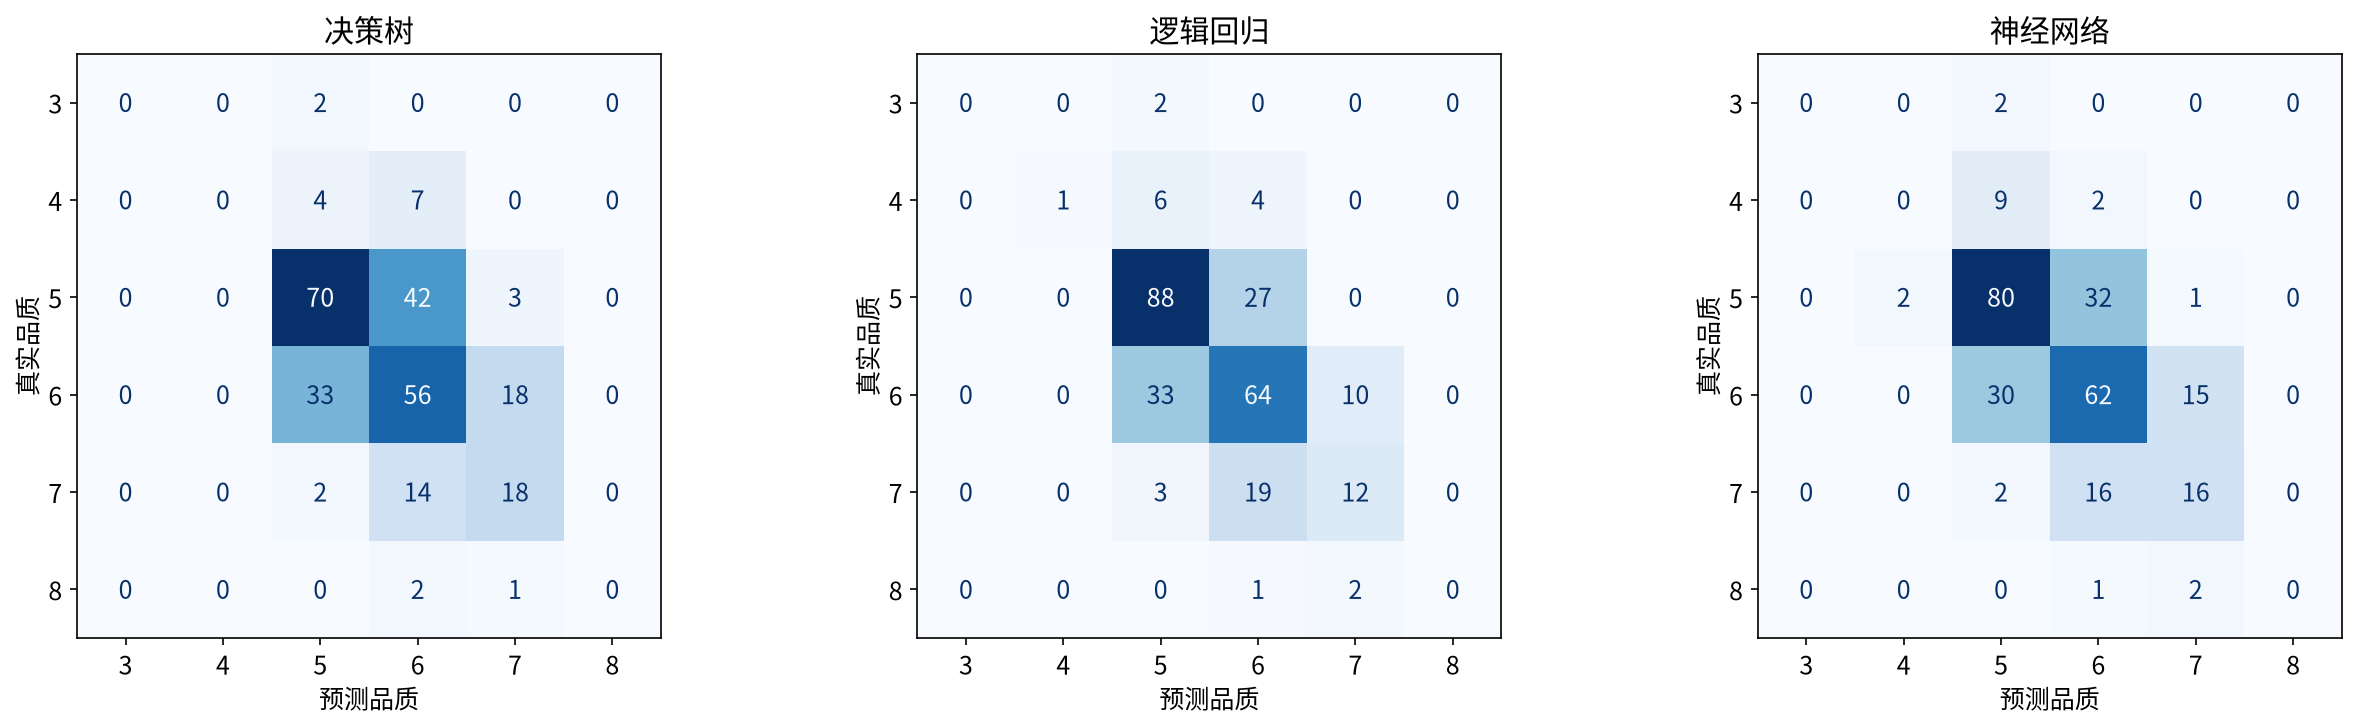

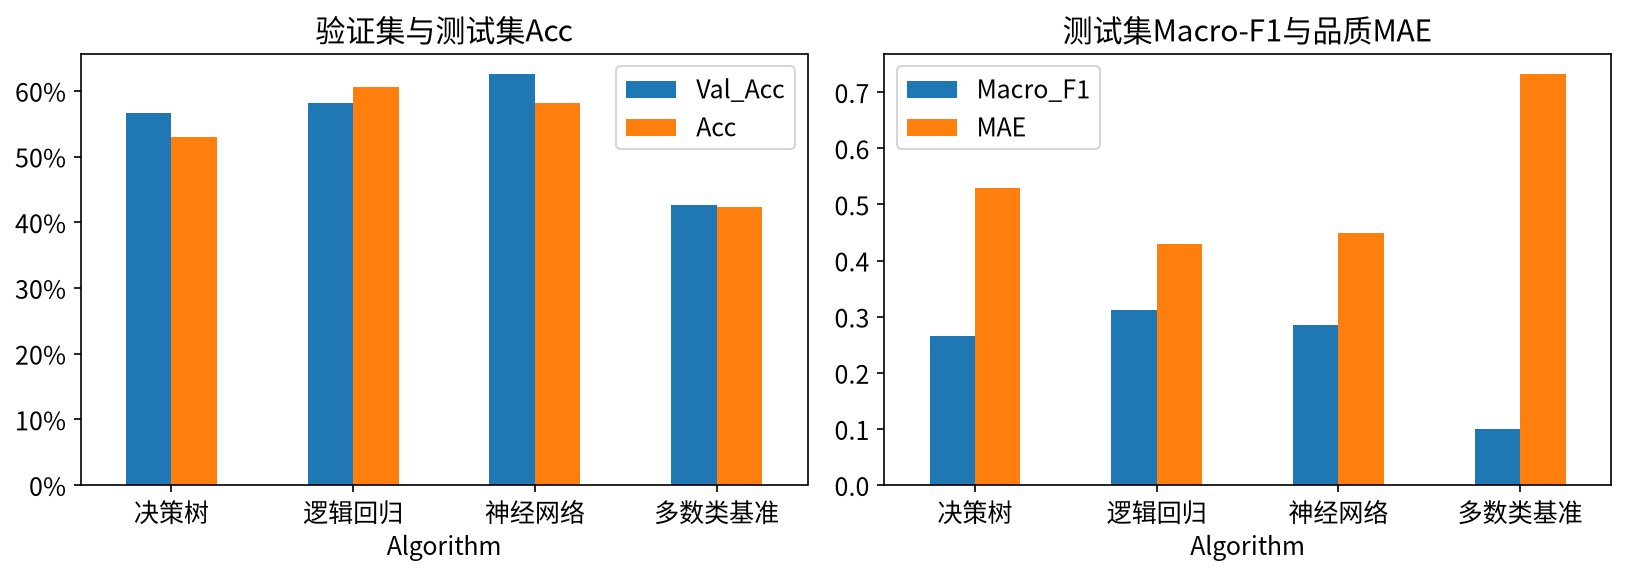

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (algorithm, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=list(range(N_CLASSES)),
                                            display_labels=quality_values, ax=ax,
                                            colorbar=False, cmap='Blues')
    ax.set_title(algorithm)
    ax.set_xlabel('预测品质')
    ax.set_ylabel('真实品质')
    print(f'\n{algorithm}测试集分类报告：')
    print(classification_report(y_test, pred, labels=list(range(N_CLASSES)),
                                target_names=[str(q) for q in quality_values],
                                zero_division=0, digits=3))
    
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
comparison_table.plot.bar(x='Algorithm', y=['Val_Acc', 'Acc'], ax=axes[0], rot=0)
comparison_table.plot.bar(x='Algorithm', y=['Macro_F1', 'MAE'], ax=axes[1], rot=0)
axes[0].set_title('验证集与测试集Acc')
axes[0].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
axes[1].set_title('测试集Macro-F1与品质MAE')
plt.tight_layout()
plt.show()

##### 3.3 保存较优模型及完整预处理信息
（1）分别保存三种较优分类器，PyTorch模型保存state_dict。标准化均值、标准差、中位数、列顺序及标签映射也一并保存，供真实新样本复用。仅加载自己生成、来源可信的模型文件。

In [ ]:
import joblib

preprocessing = {'feature_columns': feature_columns,
                 'quality_values': quality_values.tolist(),
                 'medians': medians.to_dict(),
                 'mean': scaler.mean_.tolist(), 'scale': scaler.scale_.tolist()}
(OUTPUT_DIR / 'preprocessing.json').write_text(
    json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding='utf-8')

joblib.dump(selected['决策树']['model'], OUTPUT_DIR / 'best_tree.joblib')
torch.save({'model_state_dict': selected['逻辑回归']['model'].state_dict(),
            'preprocessing': preprocessing, 'config': selected['逻辑回归']['name']},
           OUTPUT_DIR / 'best_logistic.pt')

best_nn_config = next(c for c in nn_configs if c['name'] == nn_name)
torch.save({'model_state_dict': selected['神经网络']['model'].state_dict(),
            'preprocessing': preprocessing, 'config': best_nn_config},
           OUTPUT_DIR / 'best_neural_network.pt')

(OUTPUT_DIR / 'selected_model.json').write_text(
    json.dumps({'algorithm': best_algorithm, 'config': selected[best_algorithm]['name']},
               ensure_ascii=False, indent=2), encoding='utf-8')
print('较优模型与预处理信息已保存至：', OUTPUT_DIR)

较优模型与预处理信息已保存至： outputs


（2）重新加载验证集选出的总体模型，并对前10条测试记录演示预测

In [ ]:
prep = json.loads((OUTPUT_DIR / 'preprocessing.json').read_text(encoding='utf-8'))
new_data = test_data[prep['feature_columns']].iloc[:10].fillna(pd.Series(prep['medians']))
raw = new_data.to_numpy(dtype=np.float32)
standardized = ((raw - np.asarray(prep['mean'])) / np.asarray(prep['scale'])).astype(np.float32)

if best_algorithm == '决策树':
    reloaded = joblib.load(OUTPUT_DIR / 'best_tree.joblib')
    predicted = reloaded.predict(raw)
    confidence = reloaded.predict_proba(raw).max(axis=1)
else:
    filename = 'best_logistic.pt' if best_algorithm == '逻辑回归' else 'best_neural_network.pt'
    state = torch.load(OUTPUT_DIR / filename, map_location=device, weights_only=True)
    reloaded = (LogisticNet() if best_algorithm == '逻辑回归' else
                Net(tuple(state['config']['hidden']), state['config']['dropout'])).to(device)
    reloaded.load_state_dict(state['model_state_dict'])
    reloaded.eval()
    with torch.no_grad():
        probs = reloaded(torch.as_tensor(standardized, device=device)).softmax(dim=1).cpu().numpy()
    predicted, confidence = probs.argmax(axis=1), probs.max(axis=1)

assert np.array_equal(predicted, predictions[best_algorithm][:10])
display(pd.DataFrame({'真实品质': quality_values[y_test[:10]],
                      '预测品质': quality_values[predicted], '置信度': confidence}))

summary = {'best_algorithm': best_algorithm, 'best_config': selected[best_algorithm]['name'],
           'split_sizes': [len(y_train), len(y_val), len(y_test)],
           'comparison': comparison_table.to_dict(orient='records'),
           'quality_correlation': quality_correlation.to_dict(),
           'selected': {k: v['name'] for k, v in selected.items()}}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

,真实品质,预测品质,置信度
0,5,5,0.422971
1,5,5,0.693175
2,6,6,0.580658
3,5,4,0.541583
4,5,5,0.884317
5,5,5,0.743705
6,5,5,0.556441
7,6,6,0.733047
8,5,5,0.941990
9,5,6,0.711784


1824

#### 四、模型性能分析

（1）各算法较优参数

决策树选择`depth=5, leaf=15, weight=None`，限制深度和叶子大小可以降低小样本过拟合。逻辑回归选择`logistic_l2_0.0`，本次验证结果中额外L2约束没有带来更优结果。神经网络选择`nn_64_32`，即11→64→32→6、ReLU、无Dropout、无额外L2，Adam学习率0.001、batch=64，按验证Loss早停并恢复最佳权重。

（2）较优分类器的统一测试结果

| 分类器 | 验证Acc | 测试Acc | 测试Macro-F1 | 测试Balanced Acc | 品质MAE |
| :--- | :---: | :---: | :---: | :---: | :---: |
| 决策树 | 56.62% | 52.94% | 0.2662 | 0.2769 | 0.5294 |
| 逻辑回归 | 58.09% | 60.66% | 0.3116 | 0.3012 | 0.4301 |
| 神经网络 | 62.50% | 58.09% | 0.2844 | 0.2909 | 0.4485 |
| 多数类基准 | 42.65% | 42.28% | 0.0991 | 0.1667 | 0.7316 |

验证集总体最优模型为**神经网络**（验证Acc 62.50%），所以将其保存为验证集选定的总体模型。在本次独立测试中，**逻辑回归**的测试Acc最高（60.66%），Macro-F1也较高，说明小样本理化数据上的较简单线性模型具有竞争力。

三种算法均超过多数类基准Acc 42.28%，但Macro-F1仅约0.27～0.31，Balanced Acc也偏低。结合混淆矩阵，模型主要学习样本较多的品质5和6，对稀有的3、4、8等级识别不足。
